<a href="https://colab.research.google.com/github/epro-tech-create/COU07506-labs/blob/main/COU07506_Week02_240242421899.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 COU 07506 - Digital Signal Processing
 WEEK 1 - LAB 0: Setting Up the DSP Laboratory

Name:Gasper Denis Mwansisya
Registration Number:240242421899
Class: BEng24COE
Date:25/11/2026


TASK 2.1

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

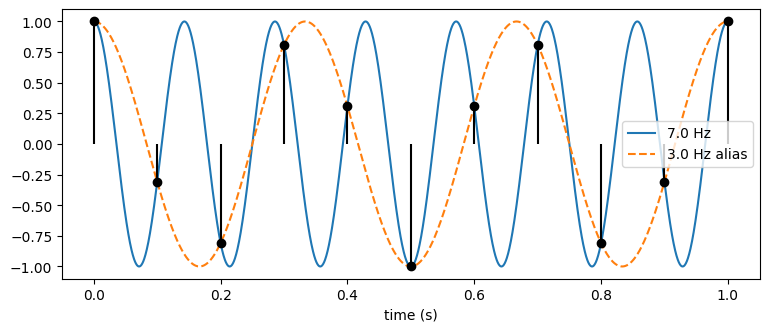

In [14]:


f0,fs = 7.0,10.0
t  = np.linspace(0, 1, 2000)

n = np.arange(0, int(fs) + 1)

# dense grid = "analog" signal
tn = n / fs
f_alias = abs(f0 - fs*round(f0/fs))
plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
plt.xlabel("time (s)"); plt.legend(); plt.show()

Sampling Rate | Nyquist Frequency | Alias Frequency
           10 |               5.0 |             3.0
           12 |               6.0 |             5.0
           14 |               7.0 |             7.0
           20 |              10.0 |             7.0


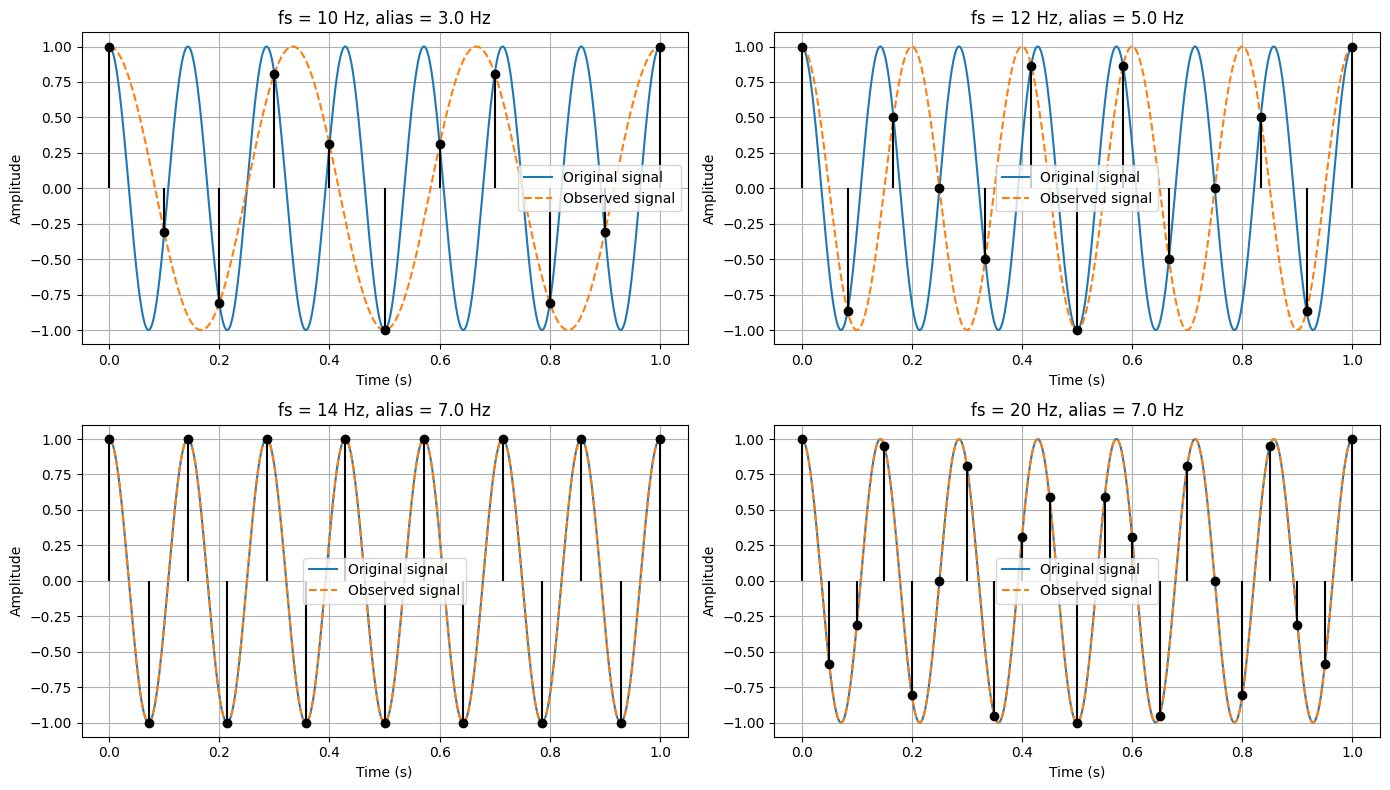

In [15]:
f0 = 7.0
t = np.linspace(0, 1, 2000)

sampling_rates = [10, 12, 14, 20]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

print("Sampling Rate | Nyquist Frequency | Alias Frequency")

for ax, fs in zip(axes.flat, sampling_rates):

    n = np.arange(0, fs + 1)
    tn = n / fs

    f_alias = abs(f0 - fs * round(f0 / fs))

    ax.plot(t, np.cos(2*np.pi*f0*t),
            label="Original signal")

    ax.plot(t, np.cos(2*np.pi*f_alias*t),
            "--", label="Observed signal")

    ax.stem(tn, np.cos(2*np.pi*f0*tn),
            linefmt="k-", markerfmt="ko",
            basefmt=" ")

    ax.set_title(f"fs = {fs} Hz, alias = {f_alias} Hz")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

    print(f"{fs:13} | {fs/2:17.1f} | {f_alias:15.1f}")

plt.tight_layout()
plt.show()

THE COMMENT FROM THE ALIASING FREQUENCY.
When the sampling frequency is below twice the original signal frequency, the sampled signal appears to have a different and lower frequency. At 14 Hz, the signal is sampled at the theoretical Nyquist rate. At 20 Hz, the sampling rate exceeds the Nyquist rate, and the original frequency is correctly represented.

Task 2.2

In [17]:
import os
from IPython.display import Audio

fname = "my_voice.wav"

if os.path.exists(fname):

    fs_audio, x_audio = wavfile.read(fname)
    x_audio = x_audio.astype(float)

    # Convert stereo to mono
    if x_audio.ndim > 1:
        x_audio = x_audio.mean(axis=1)

    # Normalize amplitude
    peak = np.max(np.abs(x_audio))

    if peak > 0:
        x_audio = x_audio / peak

    print("Using my voice recording")

else:

    # Fallback chirp signal
    fs_audio = 44100
    t_audio = np.arange(0, 3, 1/fs_audio)

    x_audio = 0.5 * signal.chirp(
        t_audio, 200, 3, 15000
    )

    print("Using fallback chirp signal")

print("Original sampling rate:", fs_audio, "Hz")

display(Audio(x_audio, rate=fs_audio))

Using my voice recording
Original sampling rate: 48000 Hz


In [18]:
for k in [2, 4, 8]:

    # Downsampling without filtering
    naive = x_audio[::k]

    # Downsampling with anti-aliasing filter
    proper = signal.decimate(
        x_audio, k, ftype="fir"
    )

    new_fs = fs_audio / k
    playback_rate = round(new_fs)

    print("\nDownsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")

    print("Without anti-aliasing filter:")
    display(Audio(naive, rate=playback_rate))

    print("With anti-aliasing filter:")
    display(Audio(proper, rate=playback_rate))


Downsampling factor: 2
New sampling rate: 24000.0 Hz
Without anti-aliasing filter:


With anti-aliasing filter:



Downsampling factor: 4
New sampling rate: 12000.0 Hz
Without anti-aliasing filter:


With anti-aliasing filter:



Downsampling factor: 8
New sampling rate: 6000.0 Hz
Without anti-aliasing filter:


With anti-aliasing filter:


Task 2.3

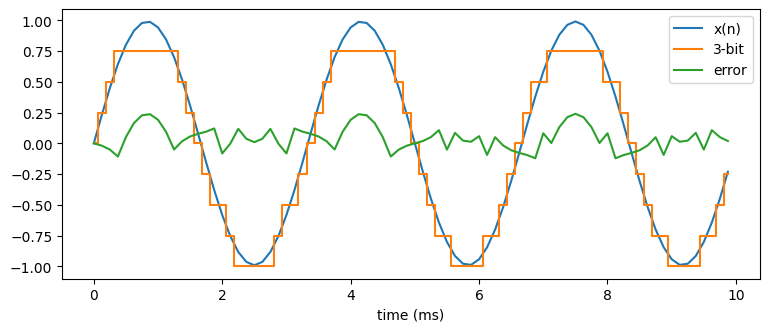

In [19]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)
plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)"); plt.legend(); plt.show()

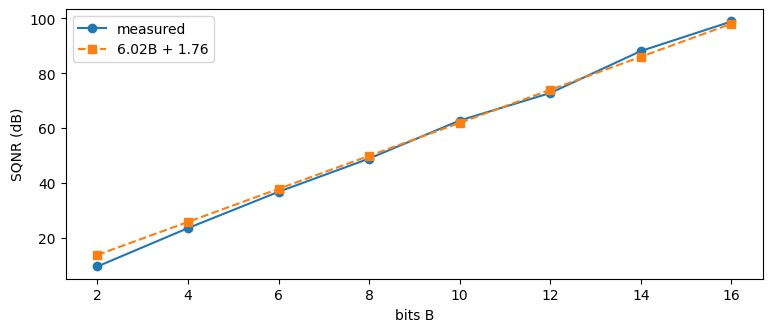

In [20]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)"); plt.legend(); plt.show()

In [21]:
voice_bits = [4, 8, 12]

for B in voice_bits:

    # Quantize audio
    audio_quantized = quantize(x_audio, B)

    # Calculate error
    error = x_audio - audio_quantized

    # Calculate SQNR
    sqnr = 10 * np.log10(
        np.sum(x_audio**2) /
        np.sum(error**2)
    )

    print(f"\nBit depth: {B} bits")
    print("Quantization levels:", 2**B)
    print(f"SQNR: {sqnr:.2f} dB")

    display(Audio(
        audio_quantized,
        rate=fs_audio,
        normalize=False
    ))


Bit depth: 4 bits
Quantization levels: 16
SQNR: 13.20 dB



Bit depth: 8 bits
Quantization levels: 256
SQNR: 30.44 dB



Bit depth: 12 bits
Quantization levels: 4096
SQNR: 54.33 dB


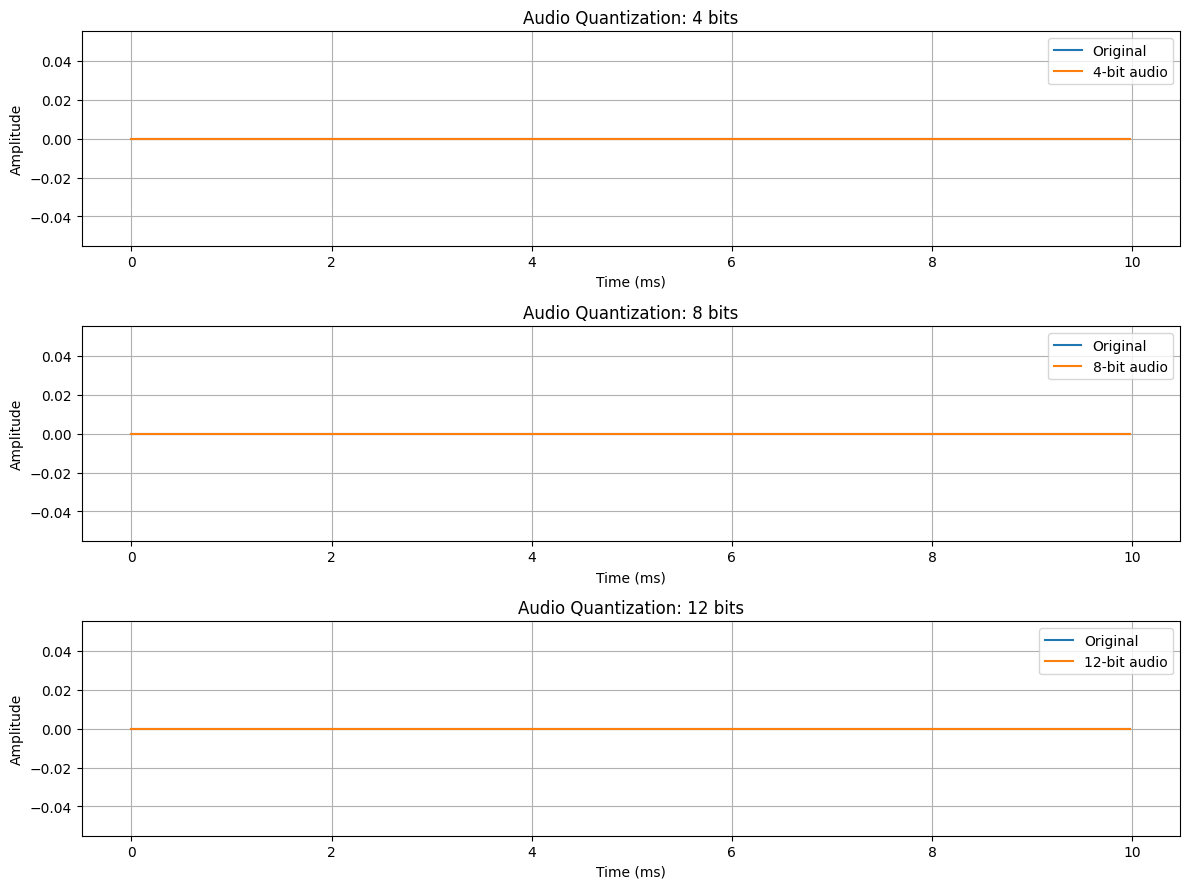

In [22]:
# Display the first 10 milliseconds
N = int(0.01 * fs_audio)

t_voice = np.arange(N) / fs_audio

fig, axes = plt.subplots(3, 1, figsize=(12, 9))

for ax, B in zip(axes, voice_bits):

    audio_quantized = quantize(x_audio, B)

    ax.plot(t_voice*1000, x_audio[:N],
            label="Original")

    ax.step(t_voice*1000, audio_quantized[:N],
            where="mid", label=f"{B}-bit audio")

    ax.set_title(f"Audio Quantization: {B} bits")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

AI tool used: ChatGPT.

Purpose:
Assistance in understanding sampling, aliasing,
quantization, Python implementation and analysis
questions.

Verification:
[Describe how the alias frequencies were checked
using mathematical calculations and how the
experimental SQNR values were compared with
the theoretical formula.]

All submitted code and results have been reviewed
and understood by me.